# Modalidade clínica: análise reproduzível

Este notebook preserva o arquivo anterior e o CSV. A classificação é **Healthy housemate versus casos incluídos no estudo**, sem confirmação presumida de PIF e sem alvo de virulência. Não há processamento de outra modalidade.

Execute as células em ordem. Instalação: `python -m pip install -r requirements_clinicos.txt`. Inicie Jupyter nesta pasta. As funções completas e suas docstrings estão em `clinica_pipeline.py`; justificativas detalhadas estão em `README_clinico.md`.


## 1. Configuração e bibliotecas

Centralize caminho, semente, folds e parâmetros. Hiperparâmetros e experimentos são pré-especificados no módulo. Não os altere após observar métricas sem tratar a nova análise como exploratória. O CSV é lido diretamente da pasta.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from clinica_pipeline import (
    Configuracao, iniciar_execucao, auditar_dados, criar_coorte,
    construir_atributos, analisar_coorte, associacoes_por_casa,
    criar_modelos, criar_pipeline, definir_folds, avaliar_modelos,
    finalizar_execucao, EXPERIMENTOS, ID, CASA, GRUPO, DIAGNOSTICO,
)

config = Configuracao()  # Para outro CSV: Configuracao(arquivo=r"C:\pasta\dados.csv")
display(pd.Series(vars(config), name="Configuração"))


arquivo                   06.2025_-_FIP_and_Housemate_Clinical_Data_Fina...
resultados                                              resultados_clinicos
semente                                                                  42
folds                                                                     5
idade_maxima                                                           30.0
repeticoes_importancia                                                   10
permutacoes_associacao                                                 1999
arvores                                                                 200
modelos                    (Dummy, Regressao_logistica, SVM, Random_forest)
Name: Configuração, dtype: object

## 2. Carregamento, esquema e proveniência

O carregamento preserva textos literais como NA. O esquema é validado; IDs ausentes/repetidos e casa ausente interrompem a análise. Cada execução cria uma pasta exclusiva, registrando versões, configurações e hashes do CSV e código.


In [2]:
dados, pasta = iniciar_execucao(config)
print(f"Dimensões: {dados.shape}; saída: {pasta.resolve()}")
display(dados.head())
display(dados.dtypes.to_frame("Tipo na importação"))


Dimensões: (100, 12); saída: C:\Users\biafr\OneDrive\Documentos\TCC\resultados_clinicos\execucao_20261018T170043_012603Z


,Home number ID,FIPID,Included/excluded and group,Diagnosis Category,"Treated at time of enrollment (Y/N) If so, how long?",Date samples collected,Sex,DOB,Breed,"Predominant clinical form (wet, dry, optho, neuro, combo)",FCoV Serology/IFA,FCoV PCR and sample type
0,1,FIPID001,Exclude - poor sample quality,Suspicious,N,4/1/2021,MI,10/24/2020,Maine Coon,Dry with mild retroperitoneal effusion,not performed,not performed
1,2,FIPID002,Exclude - poor sample quality; resampled Gandh...,Very likely,"Yes. Treatment started 4/2021, impvd within 1 wk",4/1/2021,MN,4/4/2020,DMH,Wet (pleural and retroperitoneal) + ophtho + n...,not performed,positive (kidney FNA) 3/29/2021
2,2,FIPID011,Exclude - previously treated and in remission,Very likely,"Yes. Treatment started 4/2021, impvd within 1 wk",11/10/2021,MN,4/4/2020,DMH,Wet (pleural and retroperitoneal) + ophtho + n...,not performed,positive (kidney FNA) 3/29/2021
3,2,FIPID012,Healthy housemate,NA,NA,11/10/2021,FS,4/4/2020,DSH,NA,not performed,not performed
4,3,FIPID003,Healthy housemate,NA,NA,10/4/2021,unk,unk,unk,NA,not performed,not performed


,Tipo na importação
Home number ID,str
FIPID,str
Included/excluded and group,str
Diagnosis Category,str
"Treated at time of enrollment (Y/N) If so, how long?",str
Date samples collected,str
Sex,str
DOB,str
Breed,str
"Predominant clinical form (wet, dry, optho, neuro, combo)",str


## 3. Ausências, duplicados, categorias e inconsistências

Ausência semântica inclui NA/unk/unknown/vazio; não significa resultado negativo. Arquivos exportados preservam cada categoria original e a normalização proposta. Revise diferenças de caixa/espaços e a equivalência `not perfomed/not performed` (grafia), sem alterar a entrada. Tipos de origem são texto deliberadamente; as datas serão tipadas de modo explícito.


Duplicados exatos: 0
FIPID repetidos: 0


,tipo_original,ausentes_n,ausentes_percentual,categorias_originais_n
Home number ID,str,0,0.0,52
FIPID,str,0,0.0,100
Included/excluded and group,str,0,0.0,8
Diagnosis Category,str,48,48.0,7
"Treated at time of enrollment (Y/N) If so, how long?",str,43,43.0,20
Date samples collected,str,0,0.0,55
Sex,str,17,17.0,5
DOB,str,16,16.0,75
Breed,str,19,19.0,14
"Predominant clinical form (wet, dry, optho, neuro, combo)",str,45,45.0,38


,Home number ID,FIPID,Included/excluded and group,Diagnosis Category,"Treated at time of enrollment (Y/N) If so, how long?",Date samples collected,Sex,DOB,Breed,"Predominant clinical form (wet, dry, optho, neuro, combo)",FCoV Serology/IFA,FCoV PCR and sample type
count,100,100,100,100,100,100,100,100,100,100,100,100
unique,52,100,8,7,20,55,5,75,14,38,34,42
top,3,FIPID001,Healthy housemate,NA,NA,10/4/2021,MN,unk,DSH,NA,not performed,not performed
freq,5,1,43,46,43,5,39,16,51,44,64,56


,Unnamed: 0,coluna,original,normalizado,n
0,0,Home number ID,3,3,5
1,1,Home number ID,24,24,5
2,2,Home number ID,7,7,4
3,3,Home number ID,32,32,4
4,4,Home number ID,2,2,3
...,...,...,...,...,...
445,445,FCoV PCR and sample type,positive (abd effusion) - 10/12/2023,positive (abd effusion) - 10/12/2023,1
446,446,FCoV PCR and sample type,negative (whole blood) - 10/26/2023,negative (whole blood) - 10/26/2023,1
447,447,FCoV PCR and sample type,positive (CSF) - 10/26/2023,positive (csf) - 10/26/2023,1
448,448,FCoV PCR and sample type,positive (abd effusion) - 11/9/2023,positive (abd effusion) - 11/9/2023,1


,Animais por casa
count,52.000000
mean,1.923077
std,1.026056
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,5.000000


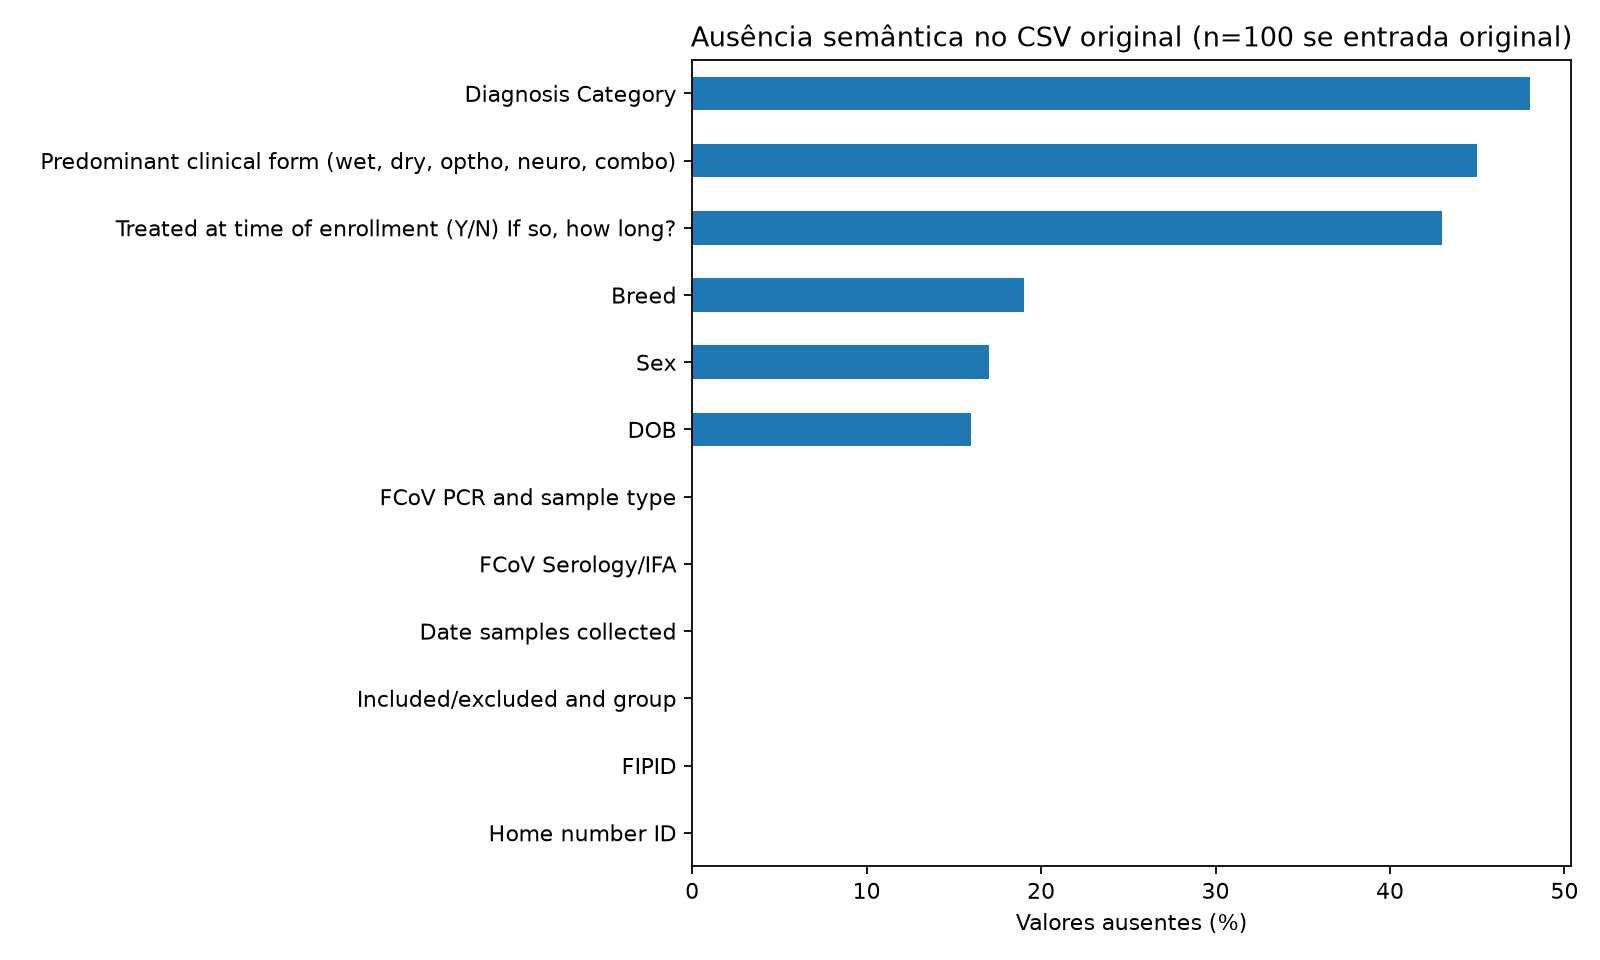

In [3]:
auditoria = auditar_dados(dados, pasta)
display(auditoria)
display(dados.describe(include="all"))
display(pd.read_csv(pasta / "categorias_originais_e_normalizadas.csv", keep_default_na=False))
print("Duplicados exatos:", dados.duplicated().sum())
print("FIPID repetidos:", dados[ID].duplicated().sum())
display(dados.groupby(CASA).size().describe().to_frame("Animais por casa"))
display(Image(filename=str(pasta / "ausentes.png")))


## 4. Inclusão, exclusão e alvo conservador

Somente Include e Healthy housemate entram. Rótulos de exclusão são validados por lista explícita. A categoria diagnóstica precisa ser compatível com o grupo; novidades interrompem a execução para revisão. Very likely/Very Likely são equivalentes de grafia, sem converter suspeita em confirmação. Grupo e categoria diagnóstica não serão preditores.


In [4]:
coorte = criar_coorte(dados, pasta)
display(coorte.groupby([GRUPO, DIAGNOSTICO]).size().rename("n"))
display(coorte.alvo.value_counts().rename(index={0: "Healthy housemate", 1: "Caso incluído"}))
print("Incluídos:", len(coorte), "Excluídos:", len(dados)-len(coorte))


Incluídos: 72 Excluídos: 28


Included/excluded and group  Diagnosis Category
Healthy housemate            NA                    43
Include                      Highly suspicious      7
                             Suspicious             6
                             Very Likely            3
                             Very likely           13
Name: n, dtype: int64

alvo
Healthy housemate    43
Caso incluído        29
Name: count, dtype: int64

## 5. Engenharia clínica e validação de datas

Idade exige nascimento e coleta válidos, em mês/dia/ano. Idades negativas, acima do limite de auditoria ou datas futuras tornam-se ausentes e são listadas para correção na fonte. Regras são determinísticas por registro, sem aprendizado no conjunto completo. Sexo/raça permanecem categorias; exames são apenas qualitativos, sem misturar títulos ou material. NA em forma clínica/tratamento não é interpretado como ausência de sinais/tratamento.


In [5]:
atributos = construir_atributos(coorte, config, pasta)
assert atributos.index.equals(coorte.index)
display(atributos.head())
display(atributos.describe(include="all"))
display(pd.read_csv(pasta / "problemas_datas.csv"))
display(pd.read_csv(pasta / "ausentes_atributos.csv"))


,idade_anos,sexo,raca,forma_clinica,sorologia,pcr,tratamento
3,1.601643,fs,dsh,NaN,nao_realizado,nao_realizado,NaN
4,NaN,NaN,NaN,NaN,nao_realizado,nao_realizado,NaN
5,NaN,NaN,NaN,NaN,nao_realizado,nao_realizado,NaN
10,NaN,NaN,NaN,NaN,nao_realizado,nao_realizado,NaN
11,NaN,NaN,NaN,NaN,nao_realizado,nao_realizado,NaN


,idade_anos,sexo,raca,forma_clinica,sorologia,pcr,tratamento
count,57.000000,56,55,29,72,72,29
unique,NaN,4,11,16,2,3,1
top,NaN,mn,dsh,wet,nao_realizado,nao_realizado,nao
freq,NaN,26,35,6,48,45,29
mean,2.950106,NaN,NaN,NaN,NaN,NaN,NaN
std,4.087624,NaN,NaN,NaN,NaN,NaN,NaN
min,0.221766,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.509240,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.804928,NaN,NaN,NaN,NaN,NaN,NaN
75%,3.022587,NaN,NaN,NaN,NaN,NaN,NaN


,Unnamed: 0,FIPID,campo,valor,motivo


,Unnamed: 0,n,percentual
0,idade_anos,15,20.833333
1,sexo,16,22.222222
2,raca,17,23.611111
3,forma_clinica,43,59.722222
4,sorologia,0,0.000000
5,pcr,0,0.000000
6,tratamento,43,59.722222


## 6. Análise exploratória por grupo

As distribuições exportadas incluem contagem e percentual dentro do grupo. A idade usa somente datas válidas, sem imputar para a descrição. A ausência de forma clínica nos controles pode ser estrutural: observe-a antes de interpretar desempenho de modelos que usam essa informação.


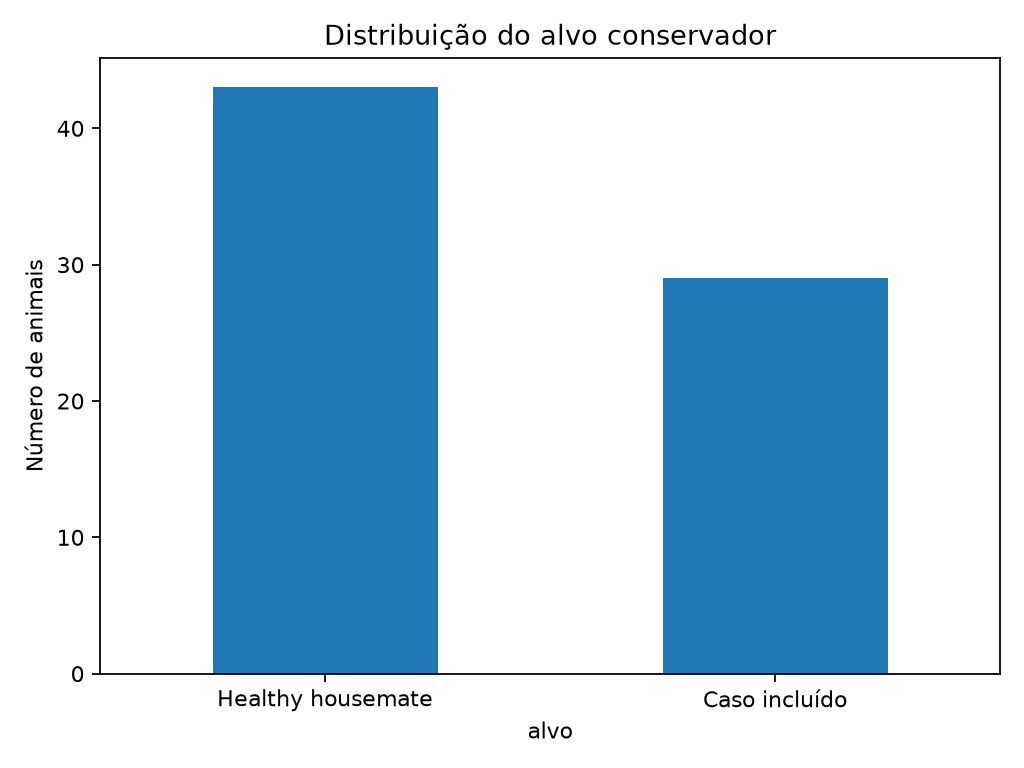

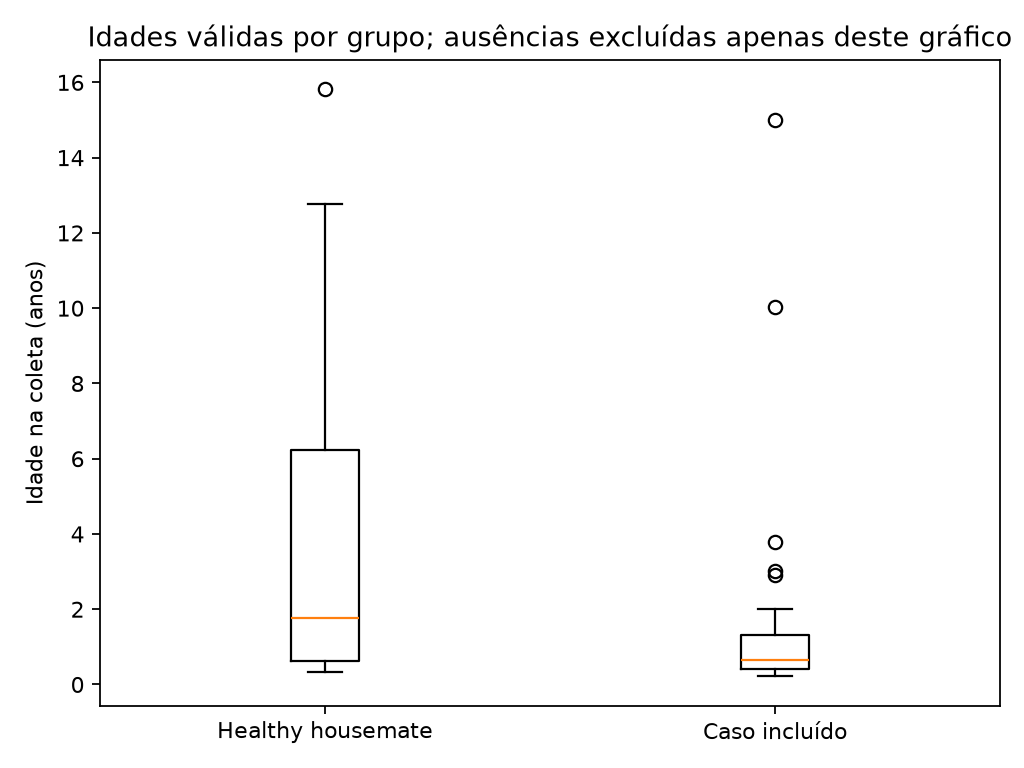

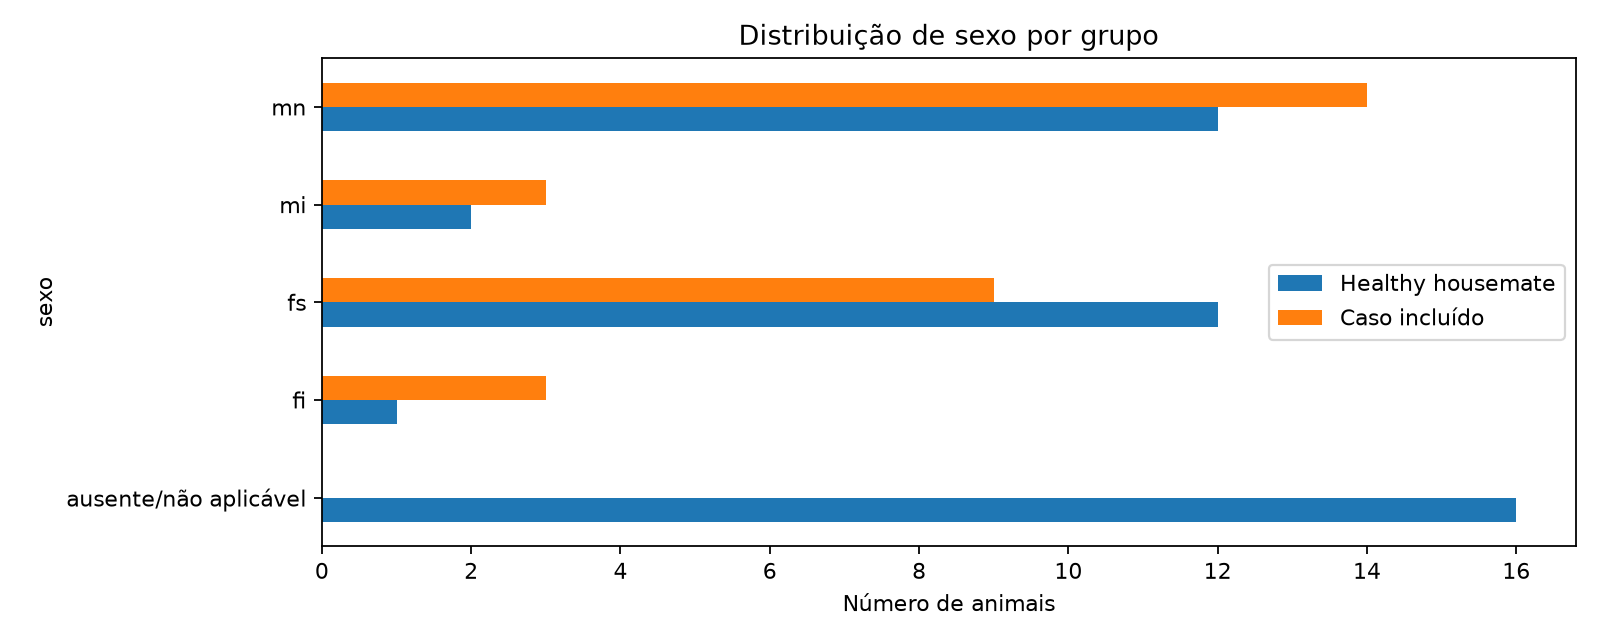

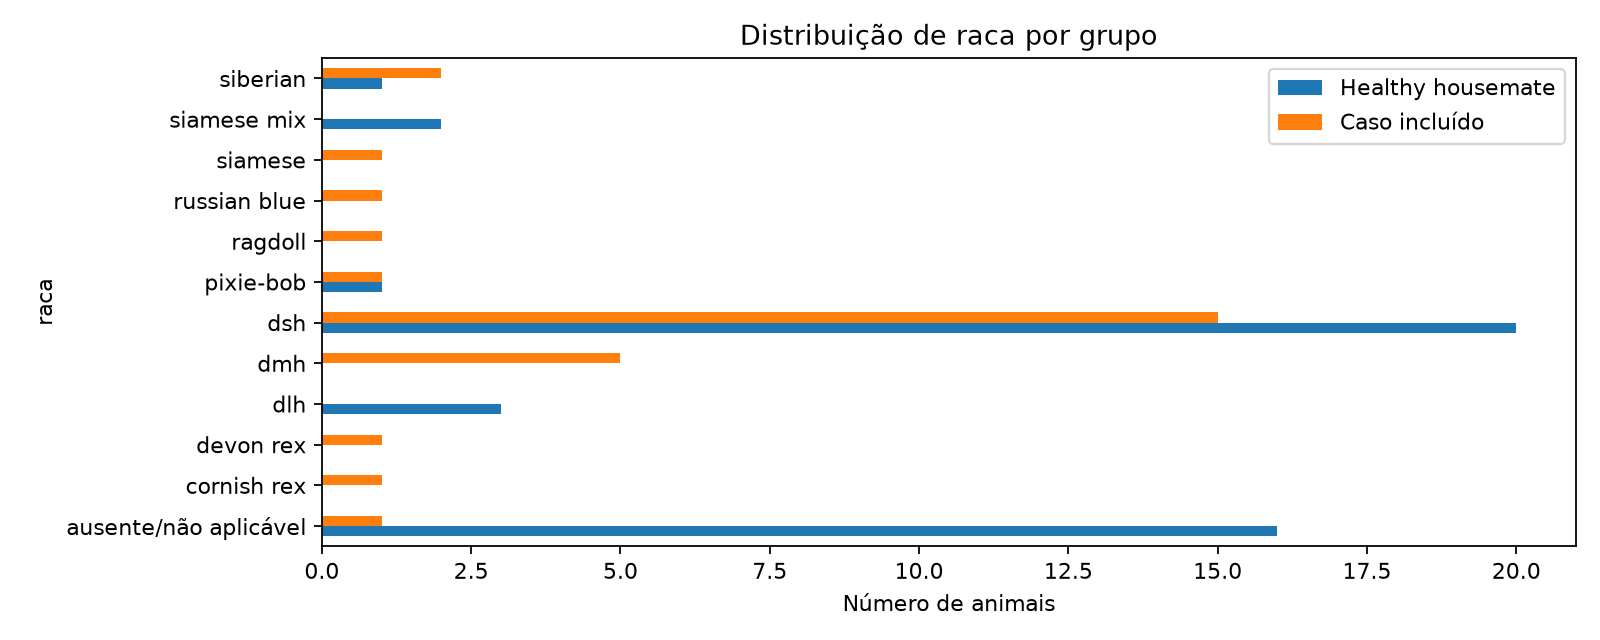

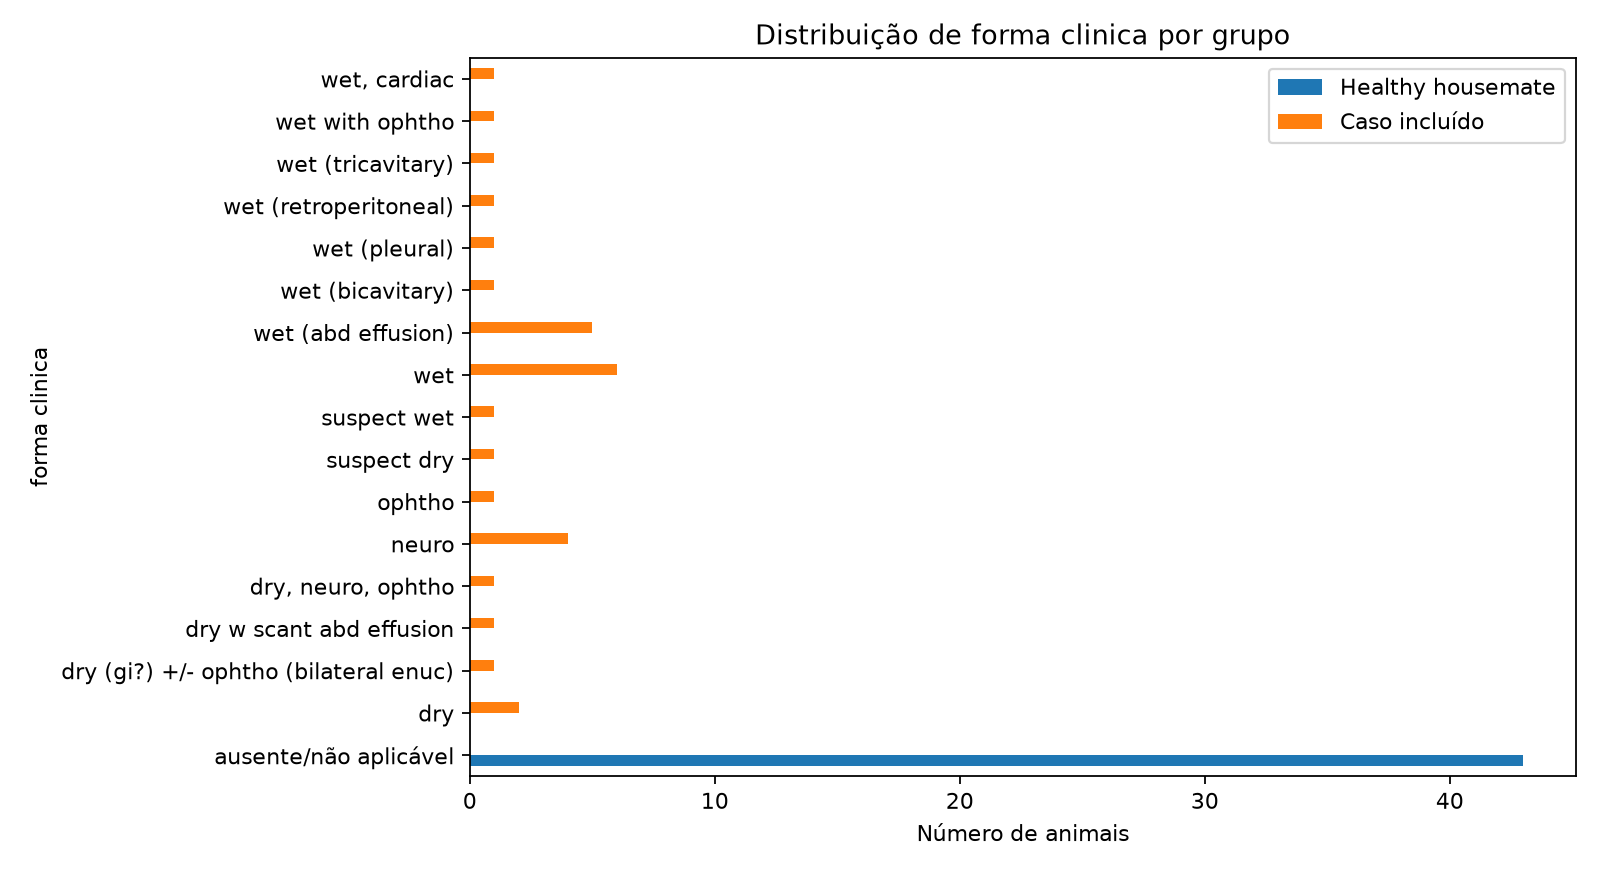

,grupo,count,mean,std,min,25%,50%,75%,max
0,0,28.0,4.158013,4.606609,0.334018,0.626283,1.756331,6.24230,15.822040
1,1,29.0,1.783851,3.175944,0.221766,0.418891,0.643395,1.32512,14.992471


In [6]:
analisar_coorte(coorte, atributos, pasta)
for nome in ["classes", "idade_grupo", "distribuicao_sexo", "distribuicao_raca", "distribuicao_forma_clinica"]:
    display(Image(filename=str(pasta / f"{nome}.png")))
display(pd.read_csv(pasta / "idade_por_grupo.csv"))


## 7. Associações exploratórias e multiplicidade

Permutações restritas dentro da casa respeitam o agrupamento, condicionadas à hipótese de permutabilidade intradomiciliar sob a hipótese nula. Usa-se diferença média de idade e qui-quadrado como estatística para categorias, com p empírico (sem aproximação de grandes amostras). Ausência categórica entra explicitamente; associações podem refletir coleta. Casas sem contraste não informam o teste. BH considera a família de variáveis exportada, com as limitações de dependência entre testes descritas no README. Não há interpretação causal.


In [7]:
associacoes = associacoes_por_casa(coorte, atributos, config, pasta)
display(associacoes)


,variavel,n,efeito,medida_efeito,estatistica_absoluta,casas_com_duas_classes,p_permutacao,q_benjamini_hochberg
0,idade_anos,57,-2.374162,diferenca_media_anos,2.374162,17,0.0535,0.053500
1,sexo,72,0.466249,V_cramer_descritivo,15.651975,17,0.0025,0.002917
2,raca,72,0.619188,V_cramer_descritivo,27.604375,17,0.0005,0.000700
3,forma_clinica,72,1.000000,V_cramer_descritivo,72.000000,17,0.0005,0.000700
4,sorologia,72,0.861034,V_cramer_descritivo,53.379310,17,0.0005,0.000700
5,pcr,72,0.943215,V_cramer_descritivo,64.055172,17,0.0005,0.000700
6,tratamento,72,1.000000,V_cramer_descritivo,72.000000,17,0.0005,0.000700


## 8. Experimentos, pré-processamento e validação por casa

Demográfico é o experimento de referência. Forma, exames e tratamento são adicionados em experimentos retrospectivos separados, pois podem revelar o processo de diagnóstico/seleção. FIPID, casa, grupo e diagnóstico nunca entram como preditores. Imputação, OneHot e padronização são ajustados dentro de cada treino. A validação é estratificada aproximadamente por classe e agrupada por casa; todo fold deve conter as duas classes. Sem busca de hiperparâmetros ou escolha antecipada de vencedor.


In [8]:
display(pd.Series(EXPERIMENTOS, name="Preditores por experimento"))
folds = definir_folds(coorte, config)
for numero, (treino, validacao) in enumerate(folds, 1):
    assert set(coorte.iloc[treino][CASA]).isdisjoint(coorte.iloc[validacao][CASA])
    print(numero, "treino:", len(treino), "validação:", len(validacao),
          "classes na validação:", coorte.iloc[validacao].alvo.value_counts().to_dict())
display(criar_pipeline(EXPERIMENTOS["demografico"], criar_modelos(config)["Regressao_logistica"]))


1 treino: 58 validação: 14 classes na validação: {0: 9, 1: 5}
2 treino: 58 validação: 14 classes na validação: {0: 8, 1: 6}
3 treino: 58 validação: 14 classes na validação: {0: 8, 1: 6}
4 treino: 57 validação: 15 classes na validação: {0: 9, 1: 6}
5 treino: 57 validação: 15 classes na validação: {0: 9, 1: 6}


demografico                                             [idade_anos, sexo, raca]
com_forma_exploratorio                   [idade_anos, sexo, raca, forma_clinica]
com_exames_exploratorio        [idade_anos, sexo, raca, forma_clinica, sorolo...
com_tratamento_exploratorio    [idade_anos, sexo, raca, forma_clinica, sorolo...
Name: Preditores por experimento, dtype: object

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerico', ...), ('categorico', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

## 9. Treinamento, métricas e previsões out-of-fold

Dummy, regressão logística, SVM linear e Random Forest usam exatamente as mesmas partições. Cada animal tem uma previsão de um modelo que não o viu no treino, nem animais da mesma casa. AUC usa probabilidade ou margem SVM; nenhuma AUC mistura margens de folds diferentes. Média e desvio-padrão entre folds não representam avaliação externa nem intervalo de confiança. Precision/F1 sem positivos previstos recebem zero.


Avaliando demografico / Dummy
Avaliando demografico / Regressao_logistica
Avaliando demografico / SVM
Avaliando demografico / Random_forest
Avaliando com_forma_exploratorio / Dummy
Avaliando com_forma_exploratorio / Regressao_logistica
Avaliando com_forma_exploratorio / SVM
Avaliando com_forma_exploratorio / Random_forest
Avaliando com_exames_exploratorio / Dummy
Avaliando com_exames_exploratorio / Regressao_logistica
Avaliando com_exames_exploratorio / SVM
Avaliando com_exames_exploratorio / Random_forest
Avaliando com_tratamento_exploratorio / Dummy
Avaliando com_tratamento_exploratorio / Regressao_logistica
Avaliando com_tratamento_exploratorio / SVM
Avaliando com_tratamento_exploratorio / Random_forest


accuracy_media  ...  roc_auc_dp
experimento                 modelo                               ...            
com_exames_exploratorio     Dummy                      0.597143  ...    0.000000
                            Random_forest              1.000000  ...    0.000000
                            Regressao_logistica        1.000000  ...    0.000000
                            SVM                        1.000000  ...    0.000000
com_forma_exploratorio      Dummy                      0.597143  ...    0.000000
                            Random_forest              1.000000  ...    0.000000
                            Regressao_logistica        0.986667  ...    0.000000
                            SVM                        1.000000  ...    0.000000
com_tratamento_exploratorio Dummy                      0.597143  ...    0.000000
                            Random_forest              1.000000  ...    0.000000
                            Regressao_logistica        1.000000  ...    0.000000
                            SVM                        1.000000  ...    0.000000
demografico                 Dummy                      0.597143  ...    0.000000
                            Random_forest              0.723810  ...    0.126882
                            Regressao_logistica        0.680952  ...    0.147909
                            SVM                        0.708571  ...    0.156397

[16 rows x 10 columns]

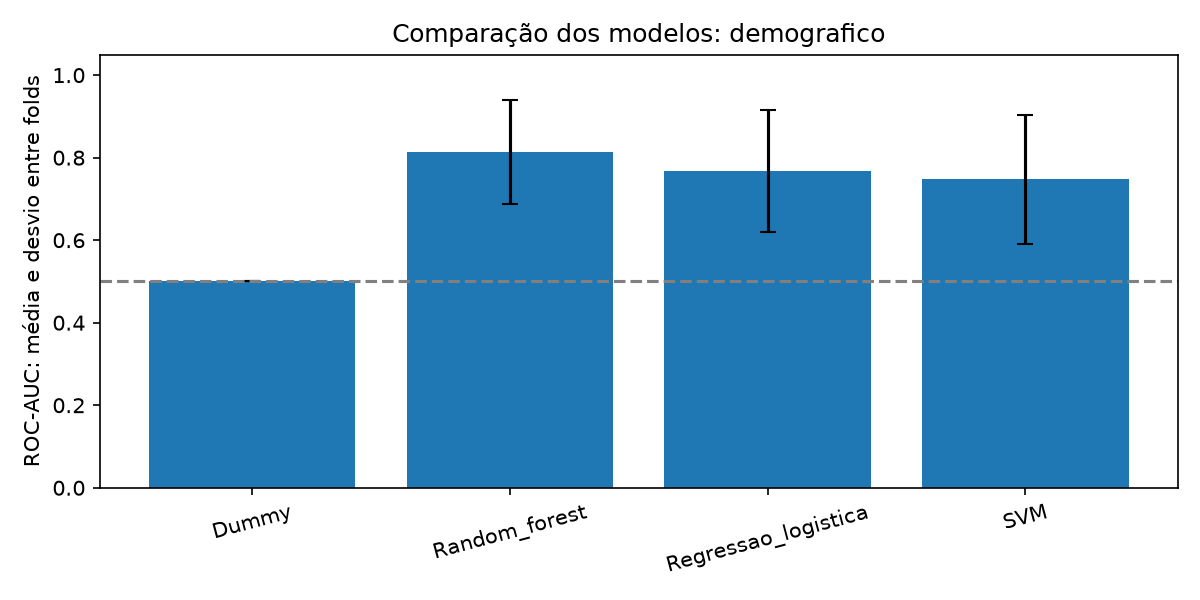

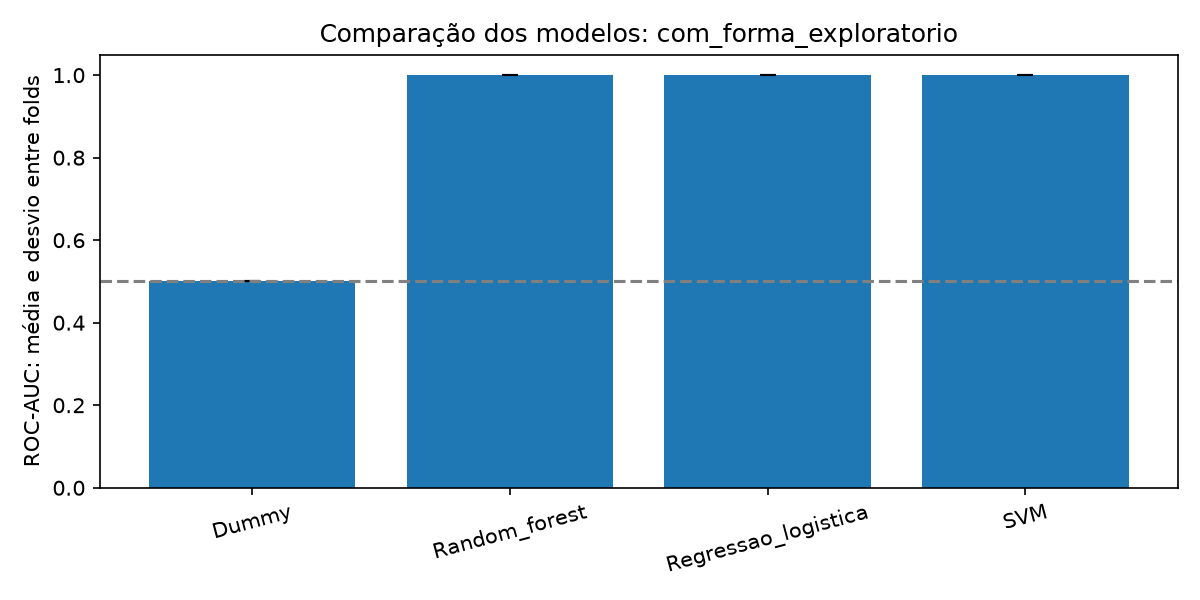

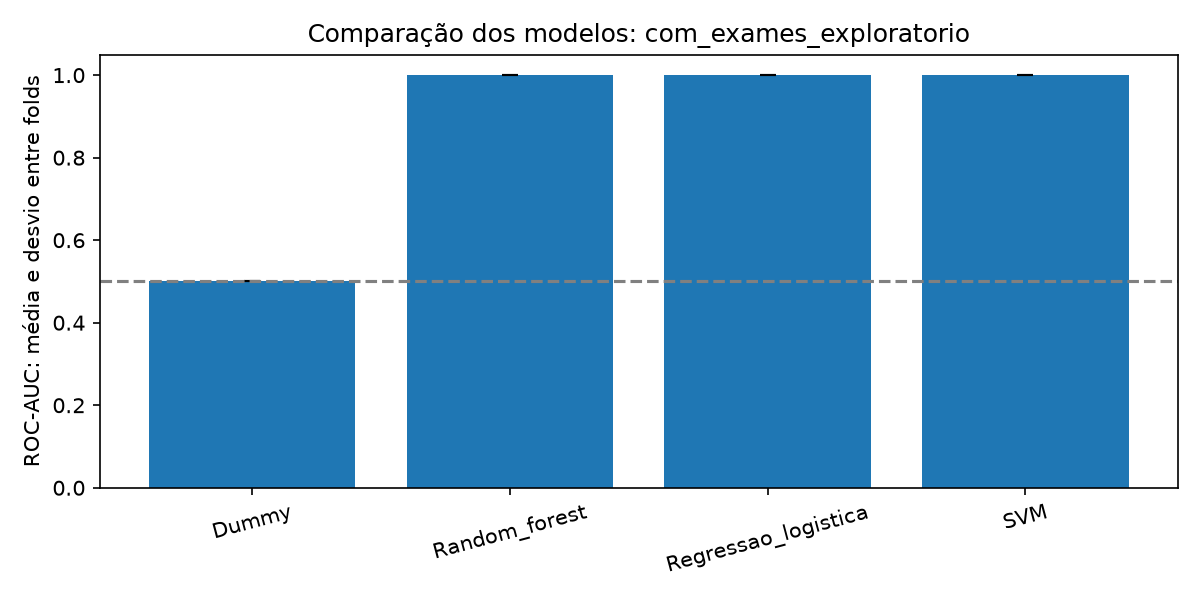

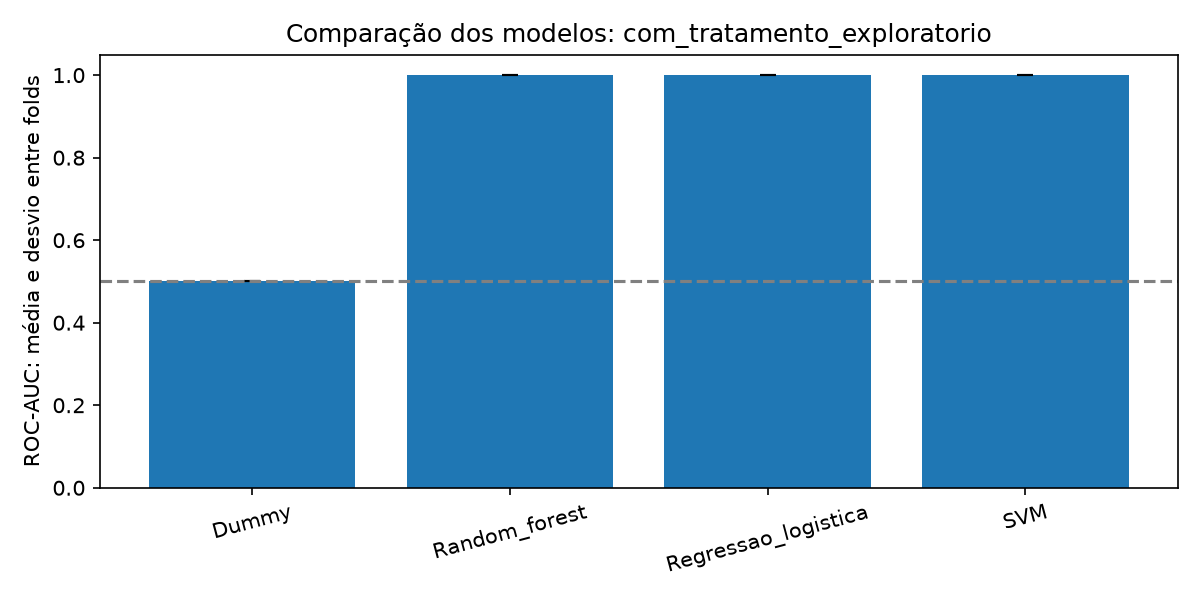

In [9]:
resumo, previsoes, metricas = avaliar_modelos(coorte, atributos, config, pasta)
display(resumo)
for experimento in EXPERIMENTOS:
    display(Image(filename=str(pasta / f"comparacao_{experimento}.png")))


## 10. Erros e interpretação das variáveis

Revise falsos positivos e negativos junto às categorias de suspeita, sem alterar o alvo após observar os erros. Importância é queda de AUC por permutação nos dados de validação; não implica causalidade ou biomarcador. A perturbação pode romper correlações entre variáveis e entre animais da casa. O resumo de importância agrega primeiro repetições dentro do fold. Coeficientes por categoria OneHot são exportados separadamente, com categorias identificadas.


,FIPID,Home number ID,Diagnosis Category,alvo,previsao,experimento,modelo,fold
17,FIPID018,8,Very Likely,1,0,demografico,Dummy,2
18,FIPID019,9,Highly suspicious,1,0,demografico,Dummy,2
22,FIPID027,11,Suspicious,1,0,demografico,Dummy,1
26,FIPID022,12,Very Likely,1,0,demografico,Dummy,4
28,FIPID031,14,Very Likely,1,0,demografico,Dummy,5
...,...,...,...,...,...,...,...,...
91,FIPID092,48,Very likely,1,0,com_tratamento_exploratorio,Dummy,5
94,FIPID096,49,Suspicious,1,0,com_tratamento_exploratorio,Dummy,2
95,FIPID095,50,Very likely,1,0,com_tratamento_exploratorio,Dummy,4
96,FIPID098,51,Very likely,1,0,com_tratamento_exploratorio,Dummy,3


,FIPID,alvo,sum,count,mean
12,FIPID022,1,8,16,0.5000
55,FIPID082,1,7,16,0.4375
9,FIPID019,1,6,16,0.3750
35,FIPID057,1,6,16,0.3750
67,FIPID096,1,5,16,0.3125
...,...,...,...,...,...
56,FIPID083,0,0,16,0.0000
64,FIPID093,0,0,16,0.0000
65,FIPID094,0,0,16,0.0000
70,FIPID099,0,0,16,0.0000


,experimento,modelo,variavel,mean,std
0,com_exames_exploratorio,Random_forest,forma_clinica,0.011667,0.013944
1,com_exames_exploratorio,Random_forest,idade_anos,0.000000,0.000000
2,com_exames_exploratorio,Random_forest,pcr,0.017389,0.024648
3,com_exames_exploratorio,Random_forest,raca,0.000000,0.000000
4,com_exames_exploratorio,Random_forest,sexo,0.000000,0.000000
5,com_exames_exploratorio,Random_forest,sorologia,0.013750,0.019961
6,com_exames_exploratorio,Regressao_logistica,forma_clinica,0.009389,0.010482
7,com_exames_exploratorio,Regressao_logistica,idade_anos,0.000000,0.000000
8,com_exames_exploratorio,Regressao_logistica,pcr,0.008778,0.011429
9,com_exames_exploratorio,Regressao_logistica,raca,0.000000,0.000000


,Unnamed: 0,experimento,modelo,fold,categoria_codificada,coeficiente
0,0,demografico,Regressao_logistica,1,numerico__idade_anos,-0.409278
1,1,demografico,Regressao_logistica,1,categorico__sexo_ausente,-1.299343
2,2,demografico,Regressao_logistica,1,categorico__sexo_fi,0.562631
3,3,demografico,Regressao_logistica,1,categorico__sexo_fs,0.042234
4,4,demografico,Regressao_logistica,1,categorico__sexo_mi,0.239289
5,5,demografico,Regressao_logistica,1,categorico__sexo_mn,0.459113
6,6,demografico,Regressao_logistica,1,categorico__raca_ausente,-0.719391
7,7,demografico,Regressao_logistica,1,categorico__raca_devon rex,0.294795
8,8,demografico,Regressao_logistica,1,categorico__raca_dlh,-0.771976
9,9,demografico,Regressao_logistica,1,categorico__raca_dmh,0.956720


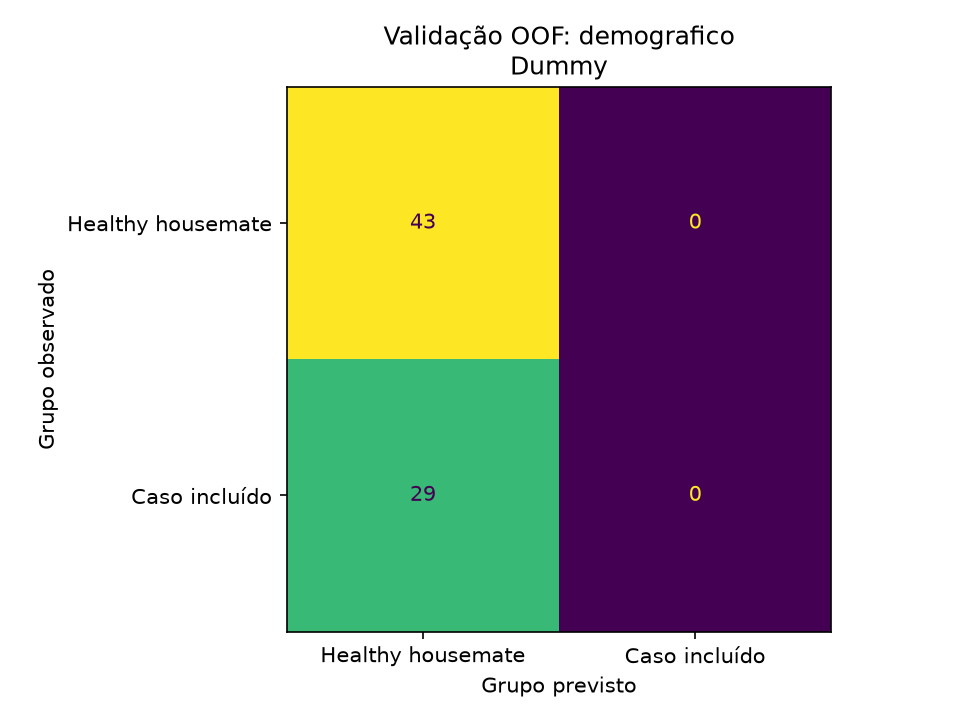

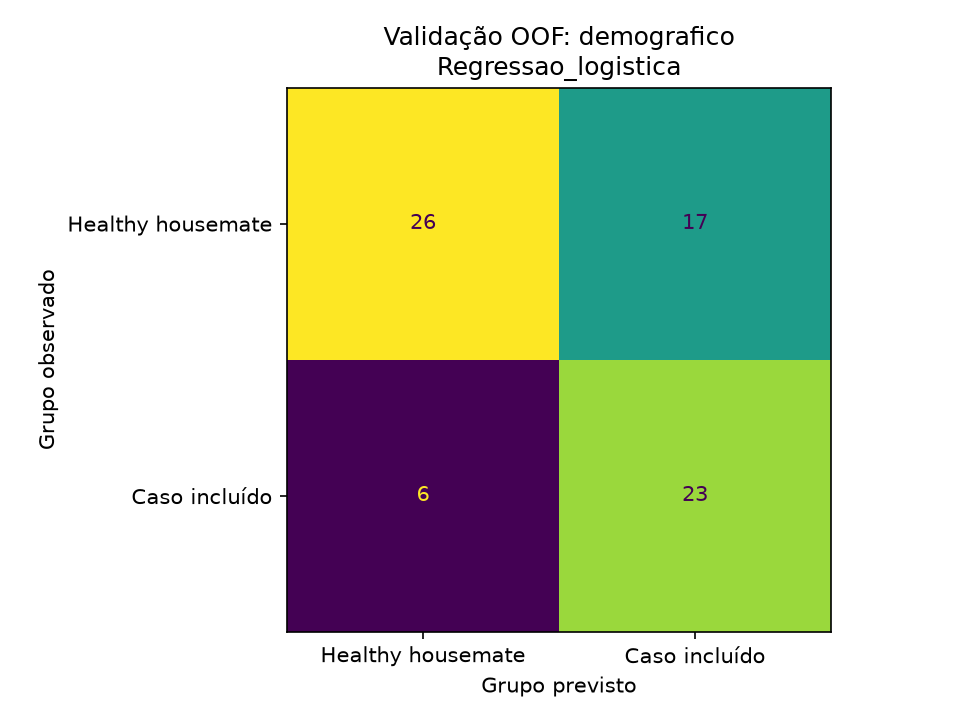

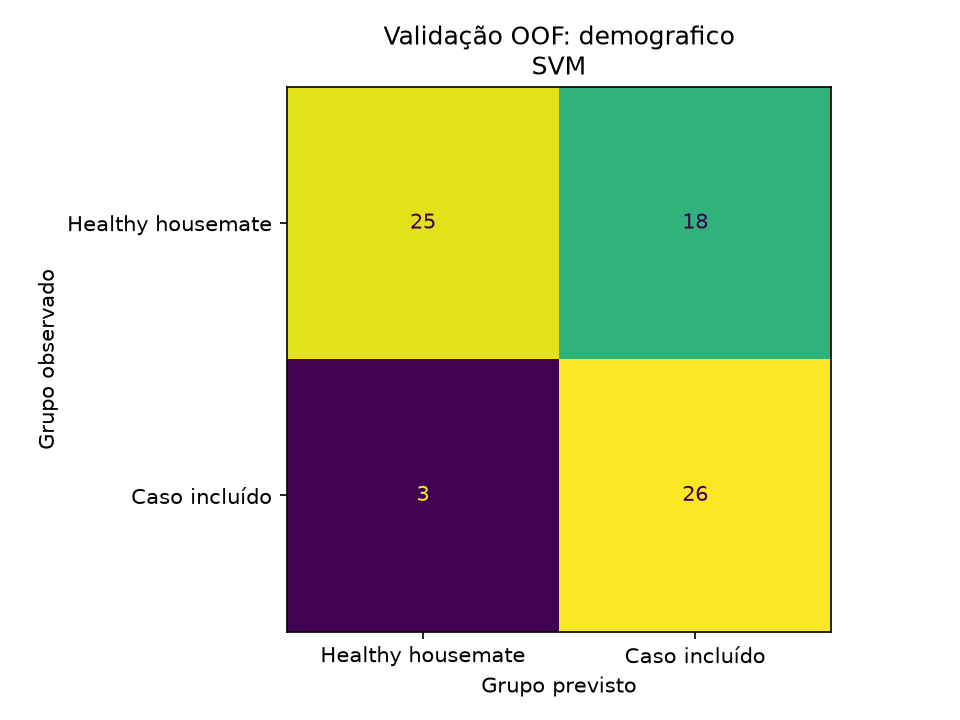

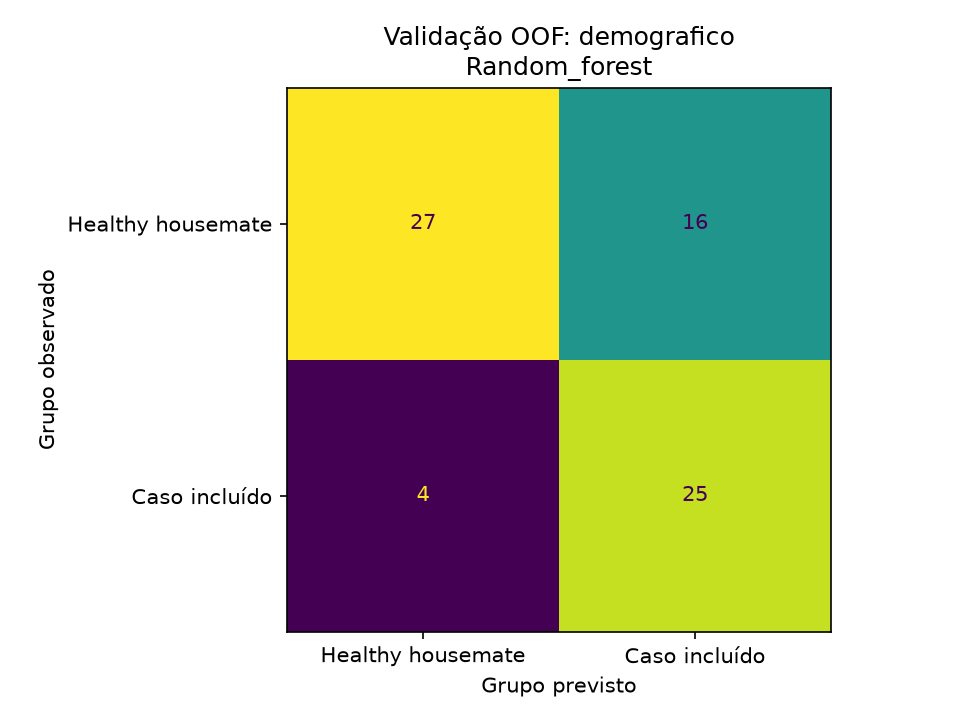

In [10]:
display(previsoes.loc[previsoes.erro, [ID, CASA, DIAGNOSTICO, "alvo", "previsao", "experimento", "modelo", "fold"]])
display(pd.read_csv(pasta / "frequencia_erros_amostra.csv").sort_values("mean", ascending=False))
display(pd.read_csv(pasta / "importancia_validacao_resumo.csv"))
display(pd.read_csv(pasta / "coeficientes_categorias_por_fold.csv").head(20))
for modelo in config.modelos:
    display(Image(filename=str(pasta / f"matriz_demografico_{modelo}.png")))


## 11. Exportação, componente reutilizável e relatório

Salva a referência pré-especificada (logística demográfica) ajustada na coorte inteira para uso futuro; esse ajuste não tem avaliação independente. A interface retorna FIPID separado de previsão/probabilidade não calibrada. Não há outra modalidade nem combinação de probabilidades. Somente carregue joblib de origem confiável.


In [11]:
finalizar_execucao(dados, coorte, atributos, resumo, metricas, associacoes, config, pasta)
display(Markdown((pasta / "RELATORIO.md").read_text(encoding="utf-8")))
print("Arquivos exportados:", len(list(pasta.iterdir())))
print(pasta.resolve())


Arquivos exportados: 101
C:\Users\biafr\OneDrive\Documentos\TCC\resultados_clinicos\execucao_20261018T170043_012603Z


# Análise clínica — relatório calculado

## Resultados calculados

Entrada: 100 registros, 12 colunas. Excluídos conforme rótulo original: 28.
Coorte: 72 animais, 43 casas; 43 Healthy housemate e 29 casos incluídos.
Idade válida em 57 animais. Validação em 5 folds, sem compartilhamento de casas.

Classe positiva: caso incluído no estudo. Desvio-padrão amostral entre folds; não é intervalo de confiança.

|Experimento|Modelo|Accuracy|Precision|Recall|F1|ROC-AUC|
|---|---|---|---|---|---|---|
|com_exames_exploratorio|Dummy|0.597 ± 0.029|0.000 ± 0.000|0.000 ± 0.000|0.000 ± 0.000|0.500 ± 0.000|
|com_exames_exploratorio|Random_forest|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_exames_exploratorio|Regressao_logistica|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_exames_exploratorio|SVM|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_forma_exploratorio|Dummy|0.597 ± 0.029|0.000 ± 0.000|0.000 ± 0.000|0.000 ± 0.000|0.500 ± 0.000|
|com_forma_exploratorio|Random_forest|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_forma_exploratorio|Regressao_logistica|0.987 ± 0.030|1.000 ± 0.000|0.967 ± 0.075|0.982 ± 0.041|1.000 ± 0.000|
|com_forma_exploratorio|SVM|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_tratamento_exploratorio|Dummy|0.597 ± 0.029|0.000 ± 0.000|0.000 ± 0.000|0.000 ± 0.000|0.500 ± 0.000|
|com_tratamento_exploratorio|Random_forest|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_tratamento_exploratorio|Regressao_logistica|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|com_tratamento_exploratorio|SVM|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|1.000 ± 0.000|
|demografico|Dummy|0.597 ± 0.029|0.000 ± 0.000|0.000 ± 0.000|0.000 ± 0.000|0.500 ± 0.000|
|demografico|Random_forest|0.724 ± 0.197|0.630 ± 0.178|0.867 ± 0.183|0.728 ± 0.181|0.814 ± 0.127|
|demografico|Regressao_logistica|0.681 ± 0.174|0.589 ± 0.160|0.800 ± 0.183|0.677 ± 0.167|0.768 ± 0.148|
|demografico|SVM|0.709 ± 0.113|0.596 ± 0.090|0.900 ± 0.149|0.715 ± 0.105|0.748 ± 0.156|

No experimento demográfico, os resultados calculados de ROC-AUC foram: Dummy: 0.500 ± 0.000; Random_forest: 0.814 ± 0.127; Regressao_logistica: 0.768 ± 0.148; SVM: 0.748 ± 0.156. As diferenças observadas não estabelecem superioridade estatística entre os modelos.
Ausência de forma clínica por grupo: Healthy housemate: 43/43; Caso incluído: 0/29. Esse padrão deve ser comparado às métricas dos experimentos ampliados antes de atribuir valor preditivo clínico.

## Interpretação e hipóteses

O experimento demográfico avalia discriminação com idade, sexo e raça. Os demais medem discriminação retrospectiva com informação do processo diagnóstico. A comparação entre esses conjuntos não demonstra ganho clinicamente disponível antes da investigação.
Forma clínica ausente/não aplicável, realização de exames e tratamento podem revelar como os grupos foram selecionados. Desempenho elevado nesses experimentos é compatível com esse viés; não comprova predição prospectiva.
Associações usam permutações de rótulos dentro da casa, com correção Benjamini–Hochberg na família de testes exportada. A permutabilidade intradomiciliar é uma hipótese; casas sem contraste não informam o teste. V de Cramér e diferença média são efeitos descritivos, sem interpretação causal.
A importância por permutação foi calculada nos folds de validação, nas variáveis originais. Quedas negativas de AUC são possíveis. Correlações e amostras pequenas tornam as importâncias instáveis; coeficientes por categoria codificada estão em arquivo separado e não são biomarcadores.

## Limitações

Não há documentação externa de confirmação diagnóstica nesta pasta. Very likely, Highly suspicious e Suspicious são graus de suspeita. Este alvo não mede PIF confirmada, prognóstico ou virulência. A grafia Very Likely é normalizada sem descartar o texto original.
Amostra pequena, recrutamento selecionado, ausência diferencial e possível correlação familiar/doméstica limitam generalização. FIPID único não garante que dois IDs não correspondam ao mesmo animal; a observação sobre recoleta no rótulo de exclusão deve ser conferida na documentação do estudo.
NA pode significar não aplicável, especialmente em controles; não é negativo nem ausência de doença. Sexo é mantido como código (MN/FS/MI/FI), sem presumir tradução não documentada. Idades dependem da precisão das datas de nascimento; o limite de 30 anos é configurável para auditoria.
Não houve otimização de hiperparâmetros. Comparar e depois escolher o maior resultado nesta mesma CV produz otimismo de seleção. Não existe teste externo nem demonstração de utilidade clínica. Probabilidades não foram calibradas; SVM produz margens. Precision/F1 indefinidas por ausência de positivos previstos recebem zero explicitamente. AUC é calculada por fold, sem agregar margens SVM de modelos diferentes em uma única AUC.
O componente serializado é a regressão logística demográfica pré-especificada, ajustada na coorte completa para reutilização; não há métrica de validação independente desse ajuste final. Carregar joblib somente de origem confiável.

## Rastreabilidade e evolução futura

Consulte configuracao_versoes.json, divisao_folds.csv, fluxo_inclusao.csv, atributos_derivados.csv e previsoes_oof.csv. Identificadores e grupo nunca entram como preditores. O CSV original permanece intacto.
Para outras modalidades serão necessários ID de animal/amostra validado, tabela de correspondência entre amostras, casa, data e momento clínico, proveniência, critérios diagnósticos, disponibilidade de cada variável no momento da previsão, consentimento e partições de validação comuns. Nenhuma outra modalidade foi implementada.

Referências técnicas: https://scikit-learn.org/stable/modules/cross_validation.html ; https://scikit-learn.org/stable/modules/permutation_importance.html

## 12. Limitações e próximos requisitos científicos

Os resultados calculados são os exibidos acima e nos arquivos da execução. Hipóteses de efeito biológico precisam de confirmação independente. O dataset é pequeno, selecionado, tem faltantes diferenciais e rótulos de suspeita. Desempenho com informação diagnóstica pode apenas recuperar critérios de seleção; **não demonstra PIF confirmada, virulência ou utilidade clínica**.

Confirme o significado de Home number ID e se existem recoletas/animais com IDs distintos; a exclusão menciona uma recoleta. A unicidade de FIPID não resolve essa questão sozinha. Antes de avançar, obtenha dicionário de dados, protocolo diagnóstico, temporalidade dos exames, origem das datas e validação externa. Para evolução futura, serão necessários identificadores de alinhamento validados, datas e momentos clínicos compatíveis, proveniência, disponibilidade das modalidades e partições compartilhadas. Nenhuma integração é implementada aqui.
